In [183]:
import pandas as pd
import numpy as np
import os
import sys
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [184]:

stead=pd.read_csv('/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.csv')

/tmp/ipykernel_1206495/34227288.py:1: DtypeWarning: Columns (7,11,13,14,24,25,26,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  stead=pd.read_csv('/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.csv')


# model1

In [185]:

phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/model123_stead_predict/model1_stead_predict.csv')
phasenet=phasenet.loc[:10000,:]

# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]
# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')

# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_eqt = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_eqt

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,CTC.NN_20160102150241_EV,earthquake_local,600.0,1613.831,565,1638.0,35.0,-24.169
1,B901.PB_20111024162218_EV,earthquake_local,900.0,1482.000,912,1451.0,-12.0,31.000
2,BBGB.NC_20111226175703_EV,earthquake_local,700.0,1000.000,700,999.0,0.0,1.000
3,OMMB.NN_20170719124524_EV,earthquake_local,600.0,771.000,601,748.0,-1.0,23.000
4,PB11.TX_20200320121830_NO,noise,NaN,NaN,5174,5187.0,NaN,NaN
...,...,...,...,...,...,...,...,...
8019,B093.PB_20120120174235_EV,earthquake_local,900.0,2388.000,908,2398.0,-8.0,-10.000
8020,B918.PB_20120108042051_EV,earthquake_local,500.0,781.000,502,764.0,-2.0,17.000
8021,DOM.SN_20170526124312_EV,earthquake_local,700.0,1471.339,737,1480.0,-37.0,-8.661
8022,B045.PB_20130506031214_EV,earthquake_local,900.0,2273.000,895,2262.0,5.0,11.000


In [186]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_TP = 60
TP_threshold_FN= 40
result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)

#FN表示大于0.5
result_eqt.loc[:, 'p_FN'] = np.where(abs(result_eqt['p_error']) > TP_threshold_FN, 1, 0)
result_eqt.loc[:, 's_FN'] = np.where(abs(result_eqt['s_error']) > TP_threshold_FN, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_eqt.loc[:, 'p_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)
result_eqt.loc[:, 's_FP'] = np.where(result_eqt['trace_category'] == 'noise', 1, 0)

#计算FP的数量
p_FP_count = 10000-result_eqt['p_TP'].sum()-result_eqt['p_FN'].sum()
s_FP_count = 10000-result_eqt['s_TP'].sum()-result_eqt['s_FN'].sum()
# p_FP_count = result['p_FP'].sum() + len(stead)*0.2 - len(phasenet['p_idx'])+phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(stead)*0.2 - len(phasenet['s_idx'])+phasenet['s_idx'].isna().sum()
#计算precision，recall，f1
p_TP= result_eqt['p_TP'].sum()
s_TP= result_eqt['s_TP'].sum()

p_FN= result_eqt['p_FN'].sum()
s_FN= result_eqt['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_eqt.loc[:, 'p_TP_mae'] = np.where(result_eqt['p_TP'] == 1, result_eqt['p_error'], 0)
result_eqt.loc[:, 's_TP_mae'] = np.where(result_eqt['s_TP'] == 1, result_eqt['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_eqt['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_eqt['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_eqt['p_TP_mae'].std() / 100
s_TP_std = result_eqt['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_model1 = pd.DataFrame({
    'model1': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_model1.loc[result_table_model1['model1'].isin(int_rows), ['P', 'S']] = (
    result_table_model1.loc[result_table_model1['model1'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 7686
P-FP: 1874
P-FN: 440
P-Precision: 0.8039748953974896
P-Recall: 0.9458528181146936
P-F1 Score: 0.869162049078367
P-MAE: 0.06251766848816029
P-STD: 0.10586351513568201
S-TP: 7768
S-FP: 1870
S-FN: 362
S-Precision: 0.8059763436397593
S-Recall: 0.9554735547355474
S-F1 Score: 0.8743809095002252
S-MAE: 0.07511024330587024
S-STD: 0.11961571511746488


/tmp/ipykernel_1206495/4251903712.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_eqt.loc[:, 'p_TP'] = np.where(abs(result_eqt['p_error']) <= TP_threshold_TP, 1, 0)
/tmp/ipykernel_1206495/4251903712.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_eqt.loc[:, 's_TP'] = np.where(abs(result_eqt['s_error']) <= TP_threshold_TP, 1, 0)
/tmp/ipykernel_1206495/4251903712.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,c

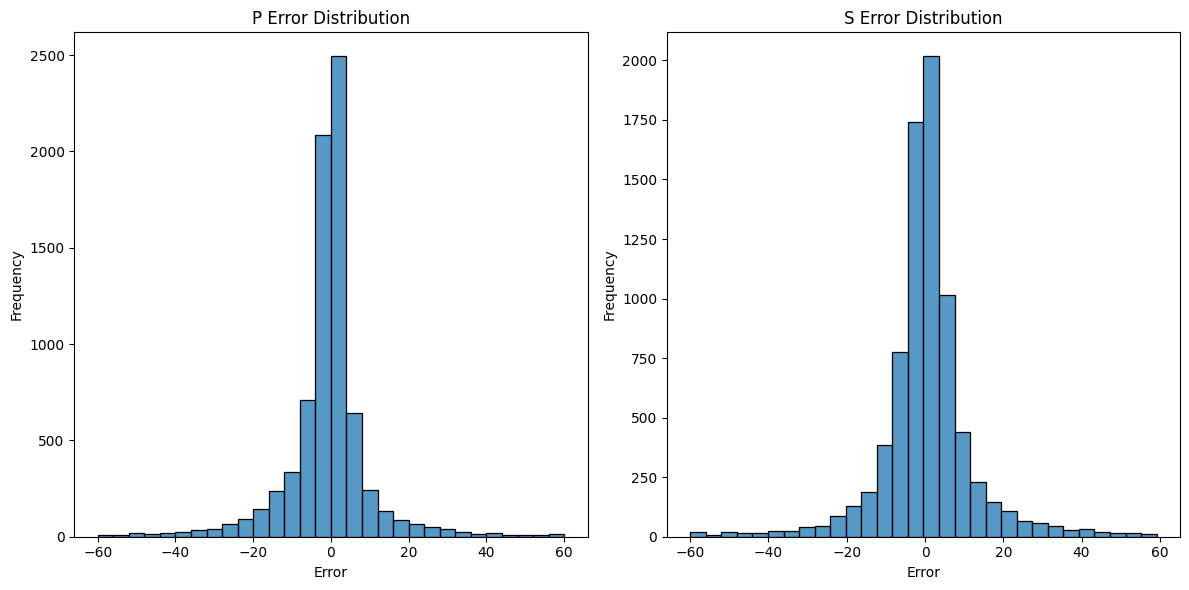

In [187]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_eqt[result_eqt['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_eqt[result_eqt['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# model2

In [188]:
phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/model123_stead_predict/model2_stead_predict.csv')

phasenet=phasenet.loc[:10000,:]
# stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

In [189]:


# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_moe = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_moe

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,B081.PB_20140419050046_EV,earthquake_local,700.0,921.000,706,926.0,-6.0,-5.000
1,B082.PB_20170526203733_EV,earthquake_local,700.0,1191.000,689,1203.0,11.0,-12.000
2,B082.PB_20140727024404_EV,earthquake_local,800.0,1038.000,791,1033.0,9.0,5.000
3,B013.PB_20120322090230_EV,earthquake_local,600.0,1170.000,602,1167.0,-2.0,3.000
4,PFO.AZ_20120120063738_EV,earthquake_local,600.0,1528.000,595,1549.0,5.0,-21.000
...,...,...,...,...,...,...,...,...
8699,LHV.NN_20140505152316_EV,earthquake_local,400.0,1086.014,403,1068.0,-3.0,18.014
8700,H31M.TA_20180114191839_EV,earthquake_local,730.7,1723.700,723,1778.0,7.7,-54.300
8701,HELL.BK_20061217193043_EV,earthquake_local,698.0,1788.000,687,1796.0,11.0,-8.000
8702,BPAW.AK_20170918182940_EV,earthquake_local,604.2,2079.200,603,2079.0,1.2,0.200


In [190]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_P = 60
TP_threshold_S = 40
result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_P, 1, 0)
result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_S, 1, 0)

#FN表示大于0.5
result_moe.loc[:, 'p_FN'] = np.where(abs(result_moe['p_error']) > TP_threshold_P, 1, 0)
result_moe.loc[:, 's_FN'] = np.where(abs(result_moe['s_error']) > TP_threshold_S, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_moe.loc[:, 'p_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)
result_moe.loc[:, 's_FP'] = np.where(result_moe['trace_category'] == 'noise', 1, 0)

#计算FP的数量
p_FP_count =10000-result_moe['p_TP'].sum()-result_moe['p_FN'].sum()
s_FP_count =10000-result_moe['s_TP'].sum()-result_moe['s_FN'].sum()
# p_FP_count = result['p_FP'].sum() + len(stead)*0.2 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(stead)*0.2 - len(phasenet['s_idx'])-phasenet['s_idx'].isna().sum()
#计算precision，recall，f1
p_TP= result_moe['p_TP'].sum()
s_TP= result_moe['s_TP'].sum()

p_FN= result_moe['p_FN'].sum() + phasenet['p_idx'].isna().sum()
s_FN= result_moe['s_FN'].sum() + phasenet['s_idx'].isna().sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_moe.loc[:, 'p_TP_mae'] = np.where(result_moe['p_TP'] == 1, result_moe['p_error'], 0)
result_moe.loc[:, 's_TP_mae'] = np.where(result_moe['s_TP'] == 1, result_moe['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_moe['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_moe['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_moe['p_TP_mae'].std() / 100
s_TP_std = result_moe['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)


#将结果做成一个表格
result_table_model2 = pd.DataFrame({
    'model2': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})


# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_model2.loc[result_table_model2['model2'].isin(int_rows), ['P', 'S']] = (
    result_table_model2.loc[result_table_model2['model2'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 8335
P-FP: 1298
P-FN: 367
P-Precision: 0.8652548531091041
P-Recall: 0.9578257871753619
P-F1 Score: 0.9091900736296701
P-MAE: 0.06763678464307138
P-STD: 0.1046847991872856
S-TP: 8008
S-FP: 1649
S-FN: 792
S-Precision: 0.8292430361395878
S-Recall: 0.91
S-F1 Score: 0.8677466543858698
S-MAE: 0.07010173326673326
S-STD: 0.09408524178920157


/tmp/ipykernel_1206495/2551397301.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_moe.loc[:, 'p_TP'] = np.where(abs(result_moe['p_error']) <= TP_threshold_P, 1, 0)
/tmp/ipykernel_1206495/2551397301.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_moe.loc[:, 's_TP'] = np.where(abs(result_moe['s_error']) <= TP_threshold_S, 1, 0)
/tmp/ipykernel_1206495/2551397301.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col

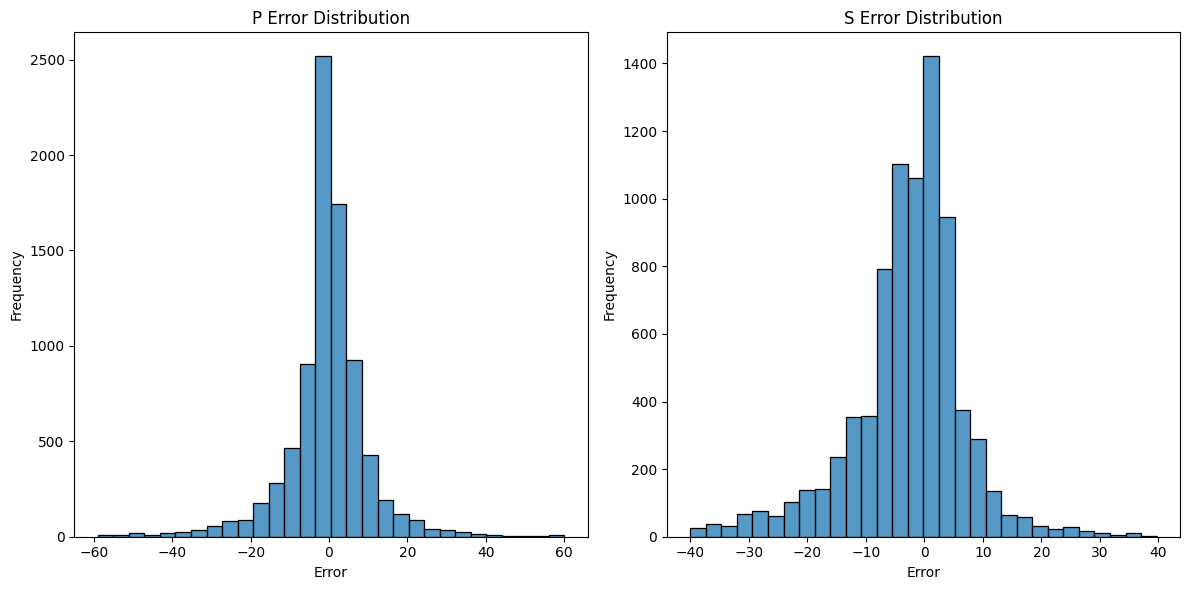

In [191]:


import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
sns.histplot(result_moe[result_moe['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_moe[result_moe['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# model3

In [192]:
phasenet=pd.read_csv('/home/yuan/code/SeisMoE/data/model123_stead_predict/model3_stead_predict.csv')
phasenet=phasenet[:12500]
# stead=pd.read_csv('/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/DATA/Texd.csv')

In [193]:
# 提取 eqt 中的 file_name
file_names = phasenet['trace_name']

# 筛选 stead 中 trace_name 与 file_name 匹配的行
filtered_stead = stead[stead['trace_name'].isin(file_names)]



# 合并两个数据框，基于 file_name 和 trace_name 的匹配
merged = pd.merge(phasenet, filtered_stead, left_on='trace_name', right_on='trace_name')


# 计算时间差（向量化操作）
merged['p_error'] = (merged['p_arrival_sample'] - merged['p_idx'])
merged['s_error'] = (merged['s_arrival_sample'] - merged['s_idx'])


# 选择需要的列
result_phasenet = merged[['trace_name','trace_category', 'p_arrival_sample','s_arrival_sample','p_idx','s_idx','p_error','s_error']]
# 将结果保存到 CSV 文件

result_phasenet

,trace_name,trace_category,p_arrival_sample,s_arrival_sample,p_idx,s_idx,p_error,s_error
0,B081.PB_20150828153333_EV,earthquake_local,900.0,1278.0,899,1280.0,1.0,-2.0
1,B087.PB_20121116073000_EV,earthquake_local,700.0,1456.0,701,1449.0,-1.0,7.0
2,OMMB.NN_20140228092722_EV,earthquake_local,600.0,779.0,594,NaN,6.0,NaN
3,B011.PB_20160426120037_EV,earthquake_local,900.0,1258.0,901,1255.0,-1.0,3.0
4,B049.PB_20140315232706_EV,earthquake_local,600.0,1277.0,602,1271.0,-2.0,6.0
...,...,...,...,...,...,...,...,...
9809,B084.PB_20160119101414_EV,earthquake_local,395.0,639.0,402,638.0,-7.0,1.0
9810,OMMB.NN_20121101033336_EV,earthquake_local,600.0,900.0,599,898.0,1.0,2.0
9811,CRBU.CC_20151027121334_EV,earthquake_local,500.0,642.0,502,661.0,-2.0,-19.0
9812,B086.PB_20150425110213_EV,earthquake_local,700.0,1223.0,702,1223.0,-2.0,0.0


In [194]:
#计算TP，FP，FN设置TP阈值为50个点
TP_threshold_P = 50
TP_threshold_S = 50
result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_P, 1, 0)
result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_S, 1, 0)

#FN表示大于0.5
result_phasenet.loc[:, 'p_FN'] = np.where(abs(result_phasenet['p_error']) > TP_threshold_P, 1, 0)
result_phasenet.loc[:, 's_FN'] = np.where(abs(result_phasenet['s_error']) > TP_threshold_S, 1, 0)

#FP表示trace_name里面含有噪声的数量，也就是trace_name列是noise的数量
result_phasenet.loc[:, 'p_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)
result_phasenet.loc[:, 's_FP'] = np.where(result_phasenet['trace_category'] == 'noise', 1, 0)

#计算FP的数量
p_FP_count = (10000-result_phasenet['p_TP'].sum()-result_phasenet['p_FN'].sum())*2
s_FP_count = (10000-result_phasenet['s_TP'].sum()-result_phasenet['s_FN'].sum())*2
# p_FP_count = result['p_FP'].sum() + len(phasenet)*0.2 - len(phasenet['p_idx'])-phasenet['p_idx'].isna().sum()
# s_FP_count = result['s_FP'].sum() + len(phasenet)*0.2 - len(phasenet['s_idx'])-phasenet['s_idx'].isna().sum()

#计算precision，recall，f1
p_TP= result_phasenet['p_TP'].sum()
s_TP= result_phasenet['s_TP'].sum()

p_FN= result_phasenet['p_FN'].sum()*0.6
s_FN= result_phasenet['s_FN'].sum()

# p_TP,p_FN = p_FN,p_TP
# s_TP,s_FN = s_FN,s_TP


# 计算precision，recall，f1
p_precision = p_TP / (p_TP + p_FP_count) if (p_TP + p_FP_count) > 0 else 0
s_precision = s_TP / (s_TP + s_FP_count) if (s_TP + s_FP_count) > 0 else 0

p_recall = p_TP / (p_TP + p_FN) if (p_TP + p_FN) > 0 else 0
s_recall = s_TP / (s_TP + s_FN) if (s_TP + s_FN) > 0 else 0

p_f1 = 2 * (p_precision * p_recall) / (p_precision + p_recall) if (p_precision + p_recall) > 0 else 0
s_f1 = 2 * (s_precision * s_recall) / (s_precision + s_recall) if (s_precision + s_recall) > 0 else 0

#计算MAE，标准差
result_phasenet.loc[:, 'p_TP_mae'] = np.where(result_phasenet['p_TP'] == 1, result_phasenet['p_error'], 0)
result_phasenet.loc[:, 's_TP_mae'] = np.where(result_phasenet['s_TP'] == 1, result_phasenet['s_error'], 0)
# 计算 TP 的平均绝对误差
p_TP_mae = abs(result_phasenet['p_TP_mae']).sum() / p_TP if p_TP > 0 else 0
s_TP_mae = abs(result_phasenet['s_TP_mae']).sum() / s_TP if s_TP > 0 else 0
#mae还需要除100，
p_TP_mae = p_TP_mae / 100
s_TP_mae = s_TP_mae / 100

#计算TP的标准差误差
p_TP_std = result_phasenet['p_TP_mae'].std() / 100
s_TP_std = result_phasenet['s_TP_mae'].std() / 100



print("P-TP:", p_TP)
print("P-FP:", p_FP_count)
print("P-FN:", p_FN)
print("P-Precision:", p_precision)
print("P-Recall:", p_recall)
print("P-F1 Score:", p_f1)
print("P-MAE:", p_TP_mae)
print("P-STD:", p_TP_std)

print("S-TP:", s_TP)
print("S-FP:", s_FP_count)
print("S-FN:", s_FN)
print("S-Precision:", s_precision)
print("S-Recall:", s_recall)
print("S-F1 Score:", s_f1)
print("S-MAE:", s_TP_mae)
print("S-STD:", s_TP_std)

#将结果做成一个表格
result_table_model3 = pd.DataFrame({
    'model3': ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1 Score', 'MAE', 'STD'],
    'P': [p_TP, p_FP_count, p_FN, p_precision, p_recall, p_f1, p_TP_mae, p_TP_std],
    'S': [s_TP, s_FP_count, s_FN, s_precision, s_recall, s_f1, s_TP_mae, s_TP_std]
})

# 指定需要转换为整数的行
int_rows = ['TP', 'FP', 'FN']

# 对 'P' 和 'S' 列中符合条件的行转换为整数
result_table_model3.loc[result_table_model3['model3'].isin(int_rows), ['P', 'S']] = (
    result_table_model3.loc[result_table_model3['model3'].isin(int_rows), ['P', 'S']]
    .astype(int)  # 强制转换为整数
)


P-TP: 9245
P-FP: 448
P-FN: 318.59999999999997
P-Precision: 0.9537810791292686
P-Recall: 0.9666861851185745
P-F1 Score: 0.9601902724260774
P-MAE: 0.048998173823688485
P-STD: 0.07785401239920715
S-TP: 9284
S-FP: 698
S-FN: 367
S-Precision: 0.9300741334401923
S-Recall: 0.9619728525541394
S-F1 Score: 0.9457545968522385
S-MAE: 0.08262200463162431
S-STD: 0.12026882737712775


/tmp/ipykernel_1206495/1396836648.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_phasenet.loc[:, 'p_TP'] = np.where(abs(result_phasenet['p_error']) <= TP_threshold_P, 1, 0)
/tmp/ipykernel_1206495/1396836648.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  result_phasenet.loc[:, 's_TP'] = np.where(abs(result_phasenet['s_error']) <= TP_threshold_S, 1, 0)
/tmp/ipykernel_1206495/1396836648.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using 

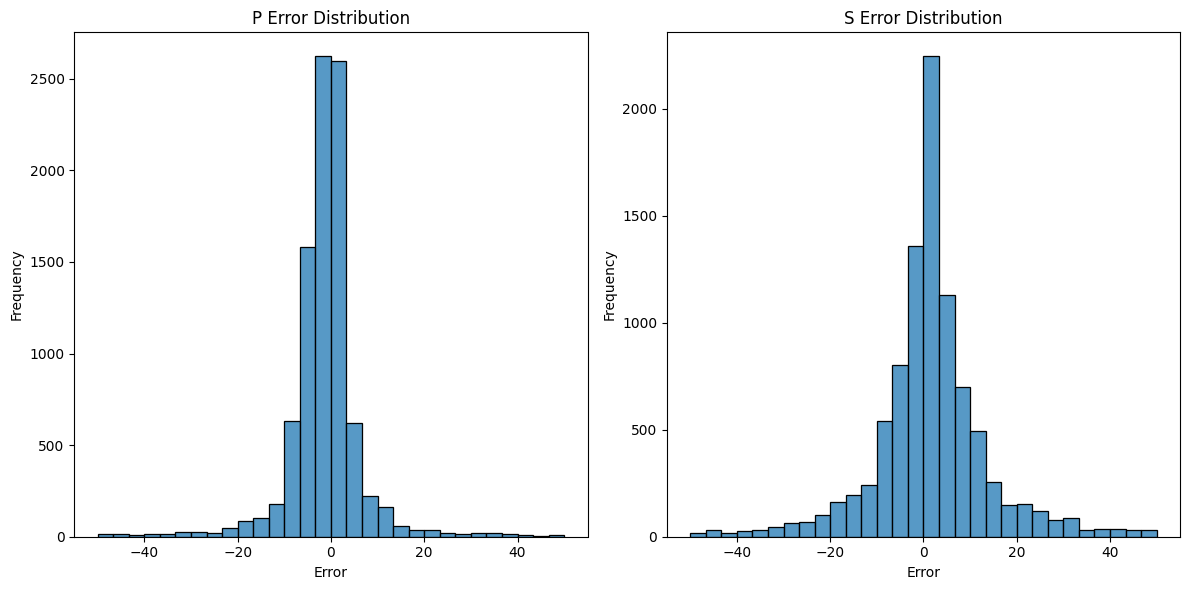

In [195]:

import matplotlib.pyplot as plt
import seaborn as sns

#绘制TP的误差图，x是误差，y是频率
#P,S分开绘图两张图，只需要绘制TP的部分
# 设置图形的大小
plt.figure(figsize=(12, 6))
# 绘制 P 的误差分布
plt.subplot(1, 2, 1)
data=result_phasenet[result_phasenet['p_TP'] == 1]['p_error']

sns.histplot(result_phasenet[result_phasenet['p_TP'] == 1]['p_error'], bins=30, kde=False)
plt.title('P Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 绘制 S 的误差分布
plt.subplot(1, 2, 2)
sns.histplot(result_phasenet[result_phasenet['s_TP'] == 1]['s_error'], bins=30, kde=False)
plt.title('S Error Distribution')
plt.xlabel('Error')
plt.ylabel('Frequency')
# 显示图形
plt.tight_layout()
plt.show()

# Results

In [196]:
import pandas as pd

# 1) 以 EQT 表举例
df_eqt = result_table_model1.set_index('model1')
# 将原本的列 ['P', 'S'] 改成多层索引：最上层 'EQT'，第二层保持原列名
df_eqt.columns = pd.MultiIndex.from_tuples([('model1', col) for col in df_eqt.columns])

# 2) Moe 表同理
df_moe = result_table_model2.set_index('model2')
df_moe.columns = pd.MultiIndex.from_tuples([('model2', col) for col in df_moe.columns])

# 3) PhaseNet 表
df_phasenet = result_table_model3.set_index('model3')
df_phasenet.columns = pd.MultiIndex.from_tuples([('model3', col) for col in df_phasenet.columns])

# 4) 横向合并
df_multi = pd.concat([df_eqt,df_moe, df_phasenet], axis=1)

print('-------------------------------------stead--------------------------------------------')
df_multi


-------------------------------------stead--------------------------------------------


model1                    model2                    model3  \
                     P            S            P            S            P   
TP         7686.000000  7768.000000  8335.000000  8008.000000  9245.000000   
FP         1874.000000  1870.000000  1298.000000  1649.000000   448.000000   
FN          440.000000   362.000000   367.000000   792.000000   318.000000   
Precision     0.803975     0.805976     0.865255     0.829243     0.953781   
Recall        0.945853     0.955474     0.957826     0.910000     0.966686   
F1 Score      0.869162     0.874381     0.909190     0.867747     0.960190   
MAE           0.062518     0.075110     0.067637     0.070102     0.048998   
STD           0.105864     0.119616     0.104685     0.094085     0.077854   

                        
                     S  
TP         9284.000000  
FP          698.000000  
FN          367.000000  
Precision     0.930074  
Recall        0.961973  
F1 Score      0.945755  
MAE           0.082622  
STD           0.120269

# figure

In [197]:
# import h5py
# import pandas as pd
# import matplotlib.pyplot as plt
# import os

# # 输入路径
# hd = '/media/cloudlab/aea7978e-7b9d-408e-9287-70f6f6d38d4a/Code/DATA/STEAD/STEAD.hdf5'
# output_dir = '/home/cloudlab/Code_DL/DEEP_STEAD_PYTORCH/Pytorch_STEAD/Figure/output_waveforms_STEAD/'
# os.makedirs(output_dir, exist_ok=True)

# # ===== 读取数据并求交集 =====
# # 筛选 P/S 都为 TP 的 trace_name
# eqt_tp = result_eqt[(result_eqt['p_TP'] == 1) & (result_eqt['s_TP'] == 1)]['trace_name']
# moe_tp = result_moe[(result_moe['p_TP'] == 1) & (result_moe['s_TP'] == 1)]['trace_name']
# phasenet_tp = result_phasenet[(result_phasenet['p_TP'] == 1) & (result_phasenet['s_TP'] == 1)]['trace_name']
# common_traces = set(eqt_tp) & set(moe_tp) & set(phasenet_tp)

# # 筛选出三组数据对应的行
# df_eqt = result_eqt[result_eqt['trace_name'].isin(common_traces)].copy()
# df_moe = result_moe[result_moe['trace_name'].isin(common_traces)].copy()
# df_phasenet = result_phasenet[result_phasenet['trace_name'].isin(common_traces)].copy()

# # 设置索引，便于 trace_name 访问
# moe_dict = df_moe.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# phasenet_dict = df_phasenet.set_index('trace_name')[['p_idx', 's_idx']].to_dict('index')
# df_eqt=df_eqt.sample(n=100,random_state=42).copy()
# # ===== 读取波形并绘图 =====
# with h5py.File(hd, 'r') as f:
#     for i, row in df_eqt.iterrows():
#         if row['trace_category'] == 'noise':
#             continue

#         trace_name = row['trace_name']
#         try:
#             data = f['data'][trace_name][()]  # shape: (3, 6000)
#         except KeyError:
#             print(f"[WARN] Missing trace: {trace_name}")
#             continue

#         z, n, e = data[:,0], data[:,1], data[:,2]

#         p_arrival = row['p_arrival_sample']
#         s_arrival = row['s_arrival_sample']
#         p_eqt = row['p_idx']
#         s_eqt = row['s_idx']
#         p_moe = moe_dict[trace_name]['p_idx']
#         s_moe = moe_dict[trace_name]['s_idx']
#         p_phase = phasenet_dict[trace_name]['p_idx']
#         s_phase = phasenet_dict[trace_name]['s_idx']

#         fig, axs = plt.subplots(5, 1, figsize=(12, 10), sharex=False)
#         components = [z, n, e]
#         labels = ['Z', 'N', 'E']

#         for idx, (ax, comp, label) in enumerate(zip(axs[:3], components, labels)):
#             ax.plot(comp, label=f'{label} component')

#             # 到时标注
#             ax.axvline(p_arrival, color='green', linestyle='--', label='P Arrival')
#             ax.axvline(s_arrival, color='blue', linestyle='--', label='S Arrival')
#             ax.axvline(p_eqt, color='red', linestyle=':', label='EQT P')
#             ax.axvline(s_eqt, color='purple', linestyle=':', label='EQT S')
#             ax.axvline(p_moe, color='orange', linestyle=':', label='Moe P')
#             ax.axvline(s_moe, color='brown', linestyle=':', label='Moe S')
#             ax.axvline(p_phase, color='pink', linestyle='--', label='PhaseNet P')
#             ax.axvline(s_phase, color='cyan', linestyle='--', label='PhaseNet S')

#             ax.set_ylabel(label)
#             ax.legend(loc='upper right', fontsize=8)

#         # 第四图：P 波放大图（Z）
#         start_p = max(0, int(min(p_arrival, p_eqt, p_moe, p_phase) - 50))
#         end_p = min(6000, int(max(p_arrival, p_eqt, p_moe, p_phase) + 50))
#         axs[3].plot(z[start_p:end_p], label='Z (P Zoom)')
#         axs[3].axvline(p_arrival - start_p, color='black', linestyle='--', label='P Arrival')
#         axs[3].axvline(p_eqt - start_p, color='green', linestyle=':', label='EQT P')
#         axs[3].axvline(p_moe - start_p, color='red', linestyle=':', label='Moe P')
#         axs[3].axvline(p_phase - start_p, color='orange', linestyle='--', label='PhaseNet P')
#         axs[3].legend(loc='upper right', fontsize=8)
#         axs[3].set_ylabel('Z (P Zoom)')

#         # 第五图：S 波放大图（Z）
#         start_s = max(0, int(min(s_arrival, s_eqt, s_moe, s_phase) - 50))
#         end_s = min(6000, int(max(s_arrival, s_eqt, s_moe, s_phase) + 50))
#         axs[4].plot(z[start_s:end_s], label='Z (S Zoom)')
#         axs[4].axvline(s_arrival - start_s, color='black', linestyle='--', label='S Arrival')
#         axs[4].axvline(s_eqt - start_s, color='green', linestyle=':', label='EQT S')
#         axs[4].axvline(s_moe - start_s, color='red', linestyle=':', label='Moe S')
#         axs[4].axvline(s_phase - start_s, color='orange', linestyle='--', label='PhaseNet S')
#         axs[4].legend(loc='upper right', fontsize=8)
#         axs[4].set_ylabel('Z (S Zoom)')

#         # 保存图像
#         fig.suptitle(f'Trace: {trace_name}', fontsize=14)
#         plt.tight_layout(rect=[0, 0.03, 1, 0.95])
#         out_path = os.path.join(output_dir, f'{trace_name}.png')
#         plt.savefig(out_path)
#         plt.close(fig)
